# CodeT5-Small (Official Weights) SFT -- Colab


## Cell 1 -- Imports & Device

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, random
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first"
sys.path.insert(0, str(DRIVE_ROOT))

%pip install -q --force-reinstall "transformers==4.44.2"

from src.codet5 import (
    TASK_TOKEN_NAME, SRTextDataset, collate_sr,
    hf_run_epoch, hf_validate, hf_greedy_decode, decode_target_text,
    parse_sr_pairs_text, apply_sr_text, join_lines, MAX_NEW_TOKENS,
)
from src.training import make_scheduler   # generic AdamW scheduler builder, architecture-agnostic

import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, T5ForConditionalGeneration
import numpy as np

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")


Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.7/41.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 115.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 141.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 65.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.8/801.8 kB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 121.6 MB/s eta 0

KeyboardInterrupt: 

## Cell 1b -- Weights & Biases

Same wandb account as the rest of the project. Project name
`codet5-official-sft` keeps this run separate from the TLM ladder's
`tlm-{s,m}-sft` dashboards, the own-pretrain CodeT5 SFT run
(`codet5-own-sft`), and this track's own bridging run
(`codet5-official-bridging`).

In [2]:
%pip install -q wandb
import wandb
wandb.login(key="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")

True

## Cell 2 -- Paths & Run Config

In [3]:
FINETUNE_DIR    = DRIVE_ROOT / "data" / "finetune_data"
FULL_TRAIN_PATH = FINETUNE_DIR / "supervised_finetuning_generated.jsonl"  # full 75k, train_domains


CODET5_BRIDGING_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / "codet5_official_bridging"

# -- RUN CONFIG -- set every time --
RUN_NAME = "codet5_official_sft"
RUN_MODE = "fresh"   # "fresh" or "resume"
assert RUN_MODE in ("fresh", "resume"), f"RUN_MODE must be 'fresh' or 'resume', got {RUN_MODE!r}"

SFT_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / RUN_NAME
SFT_CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"checkpoints -> {SFT_CKPT_DIR}")


checkpoints -> /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_official_sft


## Cell 2b -- Same-domain train/val split

In [4]:
from collections import defaultdict

SFT_TRAIN_PATH = FINETUNE_DIR / "sft_train_domain.jsonl"
SFT_VAL_PATH   = FINETUNE_DIR / "sft_val_domain.jsonl"

_VAL_FRAC   = 0.05
_SPLIT_SEED = 2025

_by_type = defaultdict(list)
with open(FULL_TRAIN_PATH, encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        rec = json.loads(line)
        _by_type[rec["type"]].append(rec)

_rng = random.Random(_SPLIT_SEED)
_train_recs, _val_recs = [], []
for ttype, recs in sorted(_by_type.items()):
    recs = recs[:]
    _rng.shuffle(recs)
    n_val = round(len(recs) * _VAL_FRAC)
    _val_recs.extend(recs[:n_val])
    _train_recs.extend(recs[n_val:])
    print(f"  {ttype:18} total {len(recs):6,}  ->  train {len(recs) - n_val:6,}  val {n_val:4,}")

_rng.shuffle(_train_recs)
_rng.shuffle(_val_recs)

with open(SFT_TRAIN_PATH, "w", encoding="utf-8") as f:
    for rec in _train_recs:
        f.write(json.dumps(rec) + "\n")
with open(SFT_VAL_PATH, "w", encoding="utf-8") as f:
    for rec in _val_recs:
        f.write(json.dumps(rec) + "\n")
print(f"wrote {len(_train_recs):,} train / {len(_val_recs):,} val -> {SFT_TRAIN_PATH.name}, {SFT_VAL_PATH.name}")


  deduplicate        total 15,000  ->  train 14,250  val  750
  extract_method     total 15,000  ->  train 14,250  val  750
  remove_dead_code   total 15,000  ->  train 14,250  val  750
  rename             total 15,000  ->  train 14,250  val  750
  simplify           total 15,000  ->  train 14,250  val  750
wrote 71,250 train / 3,750 val -> sft_train_domain.jsonl, sft_val_domain.jsonl


## Cell 3 -- Real Tokenizer, Real Pretrained Weights & Bridging Checkpoint

In [5]:
TASK_MARKER_FMT = "<{}>"
SEARCH_MARKER   = "<search>"
REPLACE_MARKER  = "<replace>"

tokenizer = AutoTokenizer.from_pretrained("Salesforce/codet5-small")
model = T5ForConditionalGeneration.from_pretrained("Salesforce/codet5-small").to(device)

new_tokens = [TASK_MARKER_FMT.format(name) for name in TASK_TOKEN_NAME.values()] + [SEARCH_MARKER, REPLACE_MARKER]
num_added = tokenizer.add_special_tokens({"additional_special_tokens": new_tokens})
model.resize_token_embeddings(len(tokenizer))
print(f"Added {num_added} new tokens: {new_tokens}")
print(f"Vocab size (incl. new tokens): {len(tokenizer)}")

PAD_ID = tokenizer.pad_token_id
print(f"pad_token={tokenizer.pad_token!r} id={PAD_ID}  |  "
      f"eos_token={tokenizer.eos_token!r} id={tokenizer.eos_token_id}  |  "
      f"bos_token={tokenizer.bos_token!r} id={tokenizer.bos_token_id}  |  "
      f"decoder_start_token_id={model.config.decoder_start_token_id}")

_ckpts = sorted(CODET5_BRIDGING_CKPT_DIR.glob("codet5_official_bridging_epoch_*_val*.pt"))
assert _ckpts, (f"No checkpoints found in {CODET5_BRIDGING_CKPT_DIR} -- run "
                 "the CodeT5 (official) bridging step first (do NOT fall back to the raw "
                 "Salesforce/codet5-small weights here).")

def _val_loss_from_name(p):
    m = re.search(r"val([0-9.]+)\.pt$", p.name)
    return float(m.group(1)) if m else float("inf")

BRIDGING_CKPT_PATH = min(_ckpts, key=_val_loss_from_name)
print(f"Found {len(_ckpts)} checkpoint(s) in {CODET5_BRIDGING_CKPT_DIR}")
print(f"Using: {BRIDGING_CKPT_PATH.name}")

_state = torch.load(BRIDGING_CKPT_PATH, map_location=device)
assert _state.get("vocab_size", len(tokenizer)) == len(tokenizer), (
    f"bridging checkpoint vocab_size={_state.get('vocab_size')} != current tokenizer "
    f"vocab_size={len(tokenizer)} -- tokenizer/new-token setup has drifted from the "
    f"bridging notebook, embeddings will not line up.")
model.load_state_dict(_state["model"])
print(f"Loaded bridging checkpoint: epoch {_state.get('epoch')}  val_loss {_state.get('val_loss')}")

n_params = sum(p.numel() for p in model.parameters())
print(f"Model params: {n_params/1e6:.3f}M")

# Gradient checkpointing -- same OOM mitigation as the rest of the ladder's SFT/bridging
# notebooks. use_cache re-enabled after training for generation (see the mini-eval cell below).
model.gradient_checkpointing_enable()
model.config.use_cache = False


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/242M [00:00<?, ?B/s]

Added 7 new tokens: ['<rename>', '<simplify>', '<deduplicate>', '<remove_dead_code>', '<extract_method>', '<search>', '<replace>']
Vocab size (incl. new tokens): 32107
pad_token='<pad>' id=0  |  eos_token='</s>' id=2  |  bos_token='<s>' id=1  |  decoder_start_token_id=0
Found 4 checkpoint(s) in /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_official_bridging
Using: codet5_official_bridging_epoch_4_val0.0453.pt
Loaded bridging checkpoint: epoch 4  val_loss 0.045266789302943235
Model params: 60.496M


## Cell 4 -- SFT Datasets & DataLoaders

In [6]:
train_ds = SRTextDataset(SFT_TRAIN_PATH, tokenizer, TASK_MARKER_FMT, SEARCH_MARKER, REPLACE_MARKER)
val_ds   = SRTextDataset(SFT_VAL_PATH, tokenizer, TASK_MARKER_FMT, SEARCH_MARKER, REPLACE_MARKER)
print(f"train: {len(train_ds):,} kept, {train_ds.dropped} dropped {train_ds.dropped_by_type}")
print(f"val:   {len(val_ds):,} kept, {val_ds.dropped} dropped {val_ds.dropped_by_type}")
print(f"train kept by type: {train_ds.kept_by_type}")
print(f"val kept by type:   {val_ds.kept_by_type}")

BATCH_SIZE       = 16
GRAD_ACCUM_STEPS = 2
EFFECTIVE_BATCH_SIZE = BATCH_SIZE * GRAD_ACCUM_STEPS
NUM_WORKERS = os.cpu_count() if torch.cuda.is_available() else 0
_PIN        = torch.cuda.is_available()
_collate    = lambda b: collate_sr(b, PAD_ID)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
print(f"train batches: {len(train_loader)}  |  val batches: {len(val_loader)}  |  "
      f"effective batch size: {EFFECTIVE_BATCH_SIZE}  |  device: {device}")


train: 71,250 kept, 0 dropped {}
val:   3,750 kept, 0 dropped {}
train kept by type: {'remove_dead_code': 14250, 'simplify': 14250, 'deduplicate': 14250, 'rename': 14250, 'extract_method': 14250}
val kept by type:   {'remove_dead_code': 750, 'rename': 750, 'simplify': 750, 'extract_method': 750, 'deduplicate': 750}
train batches: 4454  |  val batches: 235  |  effective batch size: 32  |  device: cuda


## Cell 5 -- Optimizer & Schedule


In [7]:
EPOCHS       = 25
LR           = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
GRAD_CLIP    = 1.0
PATIENCE     = 3
USE_AMP      = False   # T5 + fp16 -> NaN risk; leave off unless still OOMing after batch/accum tuning
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_available()
                               and torch.cuda.is_bf16_supported()) else None

steps_per_epoch  = len(train_loader) // GRAD_ACCUM_STEPS
total_steps      = steps_per_epoch * EPOCHS
warmup_steps     = int(total_steps * WARMUP_RATIO)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = make_scheduler(optimizer, warmup_steps, total_steps)

print(f"epochs={EPOCHS}  steps/epoch={steps_per_epoch}  total={total_steps}  "
      f"warmup={warmup_steps}  lr={LR}  effective_batch={EFFECTIVE_BATCH_SIZE}")


epochs=25  steps/epoch=2227  total=55675  warmup=2783  lr=3e-05  effective_batch=32


## Cell 6 -- Train Loop (resumable)

In [ ]:
RESUME_PATH = SFT_CKPT_DIR / "last.pt"
RUN_ID_PATH = SFT_CKPT_DIR / "wandb_run_id.txt"

best_val       = float("inf")
best_ckpt_path = None
bad_epochs     = 0
history        = []
start_epoch    = 1

if RUN_MODE == "resume":
    assert RESUME_PATH.exists(), (
        f"RUN_MODE='resume' but no last.pt found at {RESUME_PATH} -- "
        f"check RUN_NAME={RUN_NAME!r} is correct, or set RUN_MODE='fresh' to start a new run.")
    print(f"Resuming {RUN_NAME!r} from {RESUME_PATH}")
    _ckpt = torch.load(RESUME_PATH, map_location=device)
    model.load_state_dict(_ckpt["model"])
    optimizer.load_state_dict(_ckpt["optimizer"])
    scheduler.load_state_dict(_ckpt["scheduler"])
    start_epoch    = _ckpt["epoch"] + 1
    best_val       = _ckpt["best_val"]
    bad_epochs     = _ckpt["bad_epochs"]
    best_ckpt_path = Path(_ckpt["best_ckpt_path"]) if _ckpt.get("best_ckpt_path") else None
    history        = _ckpt["history"]
    wandb_run_id   = _ckpt.get("wandb_run_id") or RUN_ID_PATH.read_text().strip()
    print(f"  resuming at epoch {start_epoch}  |  best_val so far {best_val:.4f}  |  "
          f"bad_epochs {bad_epochs}/{PATIENCE}")
else:
    assert not RESUME_PATH.exists(), (
        f"RUN_MODE='fresh' but {RESUME_PATH} already exists (a previous run under "
        f"RUN_NAME={RUN_NAME!r} is in progress) -- set RUN_MODE='resume' to continue it, "
        f"pick a different RUN_NAME, or delete last.pt if you really mean to overwrite it.")
    wandb_run_id = wandb.util.generate_id()
    RUN_ID_PATH.write_text(wandb_run_id)
    print(f"Starting fresh SFT run {RUN_NAME!r} from {BRIDGING_CKPT_PATH.name}")

run = wandb.init(
    project="codet5-official-sft",
    id=wandb_run_id,
    resume="allow",
    config={
        "run_name": RUN_NAME, "run_mode": RUN_MODE, "architecture": "codet5-small (official Salesforce weights)",
        "lr": LR, "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO,
        "patience": PATIENCE, "grad_clip": GRAD_CLIP, "batch_size": BATCH_SIZE,
        "grad_accum_steps": GRAD_ACCUM_STEPS, "effective_batch_size": EFFECTIVE_BATCH_SIZE,
        "epochs": EPOCHS, "init_checkpoint": BRIDGING_CKPT_PATH.name,
    },
)

for epoch in range(start_epoch, EPOCHS + 1):
    print(f"\n=== Epoch {epoch}/{EPOCHS} ===")
    tr_loss = hf_run_epoch(model, train_loader, optimizer, scheduler, PAD_ID, device,
                           grad_accum_steps=GRAD_ACCUM_STEPS, amp_dtype=AMP_DTYPE, grad_clip=GRAD_CLIP)
    va_loss = hf_validate(model, val_loader, PAD_ID, device, amp_dtype=AMP_DTYPE)
    print(f"epoch {epoch}: train_loss {tr_loss:.4f}  val_loss {va_loss:.4f}")
    history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss})

    wandb.log({"train/loss": tr_loss, "val/loss": va_loss,
               "lr": optimizer.param_groups[0]["lr"]}, step=epoch)

    if va_loss < best_val:
        best_val = va_loss; bad_epochs = 0
        best_ckpt_path = SFT_CKPT_DIR / f"{RUN_NAME}_epoch_{epoch}_val{va_loss:.4f}.pt"
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_loss": va_loss,
                    "vocab_size": len(tokenizer)}, best_ckpt_path)
        print(f"  saved best -> {best_ckpt_path.name}")
    else:
        bad_epochs += 1
        print(f"  no improvement ({bad_epochs}/{PATIENCE})")

    torch.save({
        "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(), "epoch": epoch,
        "best_val": best_val, "bad_epochs": bad_epochs,
        "best_ckpt_path": str(best_ckpt_path) if best_ckpt_path else None,
        "history": history, "wandb_run_id": wandb_run_id,
    }, RESUME_PATH)

    if bad_epochs >= PATIENCE:
        print("early stopping.")
        break

print(f"\nbest val_loss: {best_val:.4f}")
# wandb.finish() deferred to the mini-eval cell below.


Starting fresh SFT run 'codet5_official_sft' from codet5_official_bridging_epoch_4_val0.0453.pt



=== Epoch 1/25 ===
    step 200/4454  loss=1.0321  lr=1.09e-06
    step 400/4454  loss=0.9302  lr=2.17e-06
    step 600/4454  loss=0.8384  lr=3.24e-06
    step 800/4454  loss=0.7711  lr=4.32e-06
    step 1000/4454  loss=0.7264  lr=5.40e-06
    step 1200/4454  loss=0.6885  lr=6.48e-06
    step 1400/4454  loss=0.6571  lr=7.56e-06
    step 1600/4454  loss=0.6314  lr=8.63e-06
    step 1800/4454  loss=0.6081  lr=9.71e-06
    step 2000/4454  loss=0.5887  lr=1.08e-05
    step 2200/4454  loss=0.5703  lr=1.19e-05
    step 2400/4454  loss=0.5544  lr=1.29e-05
    step 2600/4454  loss=0.5399  lr=1.40e-05
    step 2800/4454  loss=0.5263  lr=1.51e-05
    step 3000/4454  loss=0.5135  lr=1.62e-05
    step 3200/4454  loss=0.5022  lr=1.73e-05
    step 3400/4454  loss=0.4915  lr=1.83e-05
    step 3600/4454  loss=0.4814  lr=1.94e-05
    step 3800/4454  loss=0.4716  lr=2.05e-05
    step 4000/4454  loss=0.4626  lr=2.16e-05
    step 4200/4454  loss=0.4543  lr=2.26e-05
    step 4400/4454  loss=0.4462  lr=2.3

## Cell 7 -- Training Curves

history saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_official_sft/training_history.json


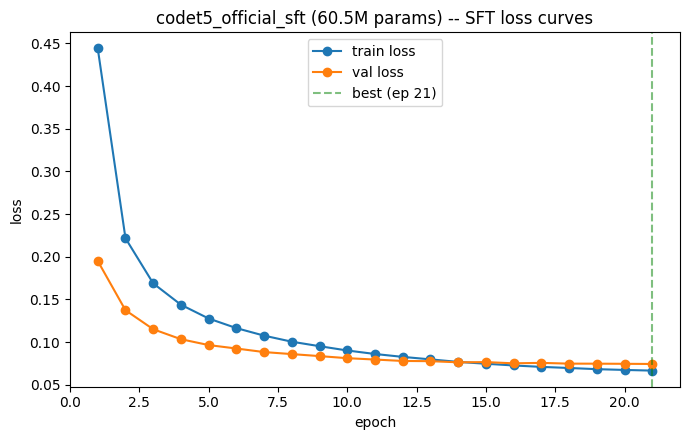

In [ ]:
import matplotlib.pyplot as plt

history_path = SFT_CKPT_DIR / "training_history.json"
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)
print(f"history saved -> {history_path}")

epochs_x   = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss   = [h["val_loss"] for h in history]
best_ep    = epochs_x[val_loss.index(min(val_loss))]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs_x, train_loss, marker="o", label="train loss")
ax.plot(epochs_x, val_loss, marker="o", label="val loss")
ax.axvline(x=best_ep, color="green", linestyle="--", alpha=0.5, label=f"best (ep {best_ep})")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title(f"{RUN_NAME} ({n_params/1e6:.1f}M params) -- SFT loss curves")
ax.legend()
plt.tight_layout()
plt.savefig(SFT_CKPT_DIR / "loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()


## Cell 8 -- Load Best Checkpoint

In [ ]:
assert best_ckpt_path is not None, "no checkpoint saved -- did training run?"
_best_state = torch.load(best_ckpt_path, map_location=device)
model.load_state_dict(_best_state["model"])
model.eval()
model.config.use_cache = True   # re-enable KV caching for generation (was off for grad checkpointing)
print(f"loaded best: {best_ckpt_path.name}  val_loss={_best_state['val_loss']:.4f}")


: 

: 

## Cell 10 -- Qualitative Samples

Same purpose as the sibling notebooks' Cell 10 -- see *why* `applied_ok` is
what it is, not just the aggregate number.

In [ ]:
N_SHOW = 4  # samples per task type


def show_qualitative(ttype, recs, n=N_SHOW, seed=0):
    rng = random.Random(seed)
    sample = rng.sample(recs, min(n, len(recs)))
    for d in sample:
        task_marker = TASK_MARKER_FMT.format(ttype)
        enc_text = task_marker + d["before"]
        enc_ids = tokenizer(enc_text, truncation=True, max_length=512).input_ids

        pred_ids = hf_greedy_decode(model, tokenizer, enc_ids, device)
        pred_text, is_trunc = decode_target_text(tokenizer, pred_ids)
        hunks = parse_sr_pairs_text(pred_text, SEARCH_MARKER, REPLACE_MARKER)
        pred_after = apply_sr_text(d["before"], hunks)

        is_ok = pred_after is not None and pred_after == d["after"]
        # hunks are (List[str], List[str]) -- lists aren't hashable, join to strings first
        hunk_keys = [(join_lines(s), join_lines(r)) for s, r in hunks]
        has_dup = len(hunk_keys) != len(set(hunk_keys))

        print(f"\n{'='*64}")
        print(f"  [{ttype.upper()}]  {'OK' if is_ok else 'WRONG/FAIL'}  "
              f"trunc={is_trunc}"
              f"{'  ** DUPLICATE HUNK **' if has_dup else ''}")
        print(f"{'='*64}")
        print(f"\nBEFORE:\n{d['before']}")
        for k, (s, r) in enumerate(hunks):
            print(f"  SEARCH  [{k+1}]: {join_lines(s)!r}")
            print(f"  REPLACE [{k+1}]: {join_lines(r)!r}")
        print(f"\nPRED AFTER:\n{pred_after if pred_after is not None else '(apply_sr_text failed)'}")
        print(f"\nGOLD AFTER:\n{d['after']}")


by_type_eval = {}
with open(SFT_VAL_PATH, encoding="utf-8") as f:
    for line in f:
        d = json.loads(line)
        by_type_eval.setdefault(d["type"], []).append(d)

for ttype in ["rename", "simplify", "deduplicate", "remove_dead_code", "extract_method"]:
    if ttype not in by_type_eval:
        continue
    print(f"\n\n{'#'*70}\n#  {ttype.upper()}\n{'#'*70}")
    show_qualitative(ttype, by_type_eval[ttype], n=N_SHOW, seed=0)
